In [1]:
import warnings
warnings.filterwarnings('ignore')

In [1]:
from clickhouse_driver import Client
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 


client = Client(host='', port=00, user='',
                password='', database='')

def get_data(query):
    """
    Вытягивает данные из clickhouse в виде Dataframe
    
    query - запрос
    """
    result, columns = client.execute(query, with_column_types=True)
    return pd.DataFrame(result, columns=[tuple[0] for tuple in columns])


In [3]:


df = get_data(f"""
    WITH la AS (
        SELECT
            la.passport_id
            , COUNT(DISTINCT la.advert_id) as n_ads
            , min(la.created_at) as first_ad
            , AVG(la.price) as mean_price
            , AVG(CAST(la.year AS INTEGER)) as mean_year
        FROM hardda.live_adverts as la
        WHERE 1=1
            AND region = 'Омск'
            AND price > 1000
            AND year != '0'
        GROUP BY la.passport_id
    ),
    ut as (
        SELECT 
            ut.passport_id
            , COUNT(DISTINCT type) as n_types
            , SUM(sign) as top_type
            , AVG(balance_consumption) as mean_transaction
        FROM hardda.user_transactions as ut
        GROUP BY ut.passport_id
    ),
    up as (
        SELECT
            *  
        FROM hardda.user_passports as up
        )


SELECT 
    * 
FROM up
INNER JOIN la
    USING(passport_id)
INNER JOIN ut
    USING(passport_id)
WHERE 1=1
    AND up.execution_date = '2023-01-31'

""")

In [4]:
df.head()

,passport_id,execution_date,global_id,created_at,user_type_id,user_type_name,user_type_changed_at,user_type_cars_id,user_type_cars_name,user_type_cars_changed_at,n_ads,first_ad,mean_price,mean_year,n_types,top_type,mean_transaction
0,141000947,2023-01-31,145684778,2021-04-02 01:19:41,0,simple_user,2106-02-07 06:28:16,0,cars_simple,2106-02-07 06:28:16,4,2021-11-06 21:03:34,236211.764706,2009.364706,7,45,131.735043
1,143033394,2023-01-31,148077734,2022-02-09 13:31:16,0,simple_user,2106-02-07 06:28:16,0,cars_simple,2106-02-07 06:28:16,1,2022-02-09 07:31:59,370000.000000,1993.000000,1,1,0.000000
2,134343899,2023-01-31,138122166,2019-02-28 17:59:46,0,simple_user,2106-02-07 06:28:16,0,cars_simple,2106-02-07 06:28:16,4,2022-05-14 07:04:02,375294.117647,2016.000000,4,3,101.111111
3,125465352,2023-01-31,125451542,2015-07-26 13:29:31,0,simple_user,2106-02-07 06:28:16,0,cars_simple,2106-02-07 06:28:16,1,2022-07-25 16:06:45,828333.333333,2012.000000,2,8,31.666667
4,137403627,2023-01-31,142335613,2020-03-27 17:42:23,0,simple_user,2106-02-07 06:28:16,0,cars_simple,2106-02-07 06:28:16,3,2021-06-08 06:48:47,86153.846154,1995.461538,4,0,130.000000


In [5]:
df.shape[0]

30703

Создайте признак days_ago типа int, который содержит количество дней, которое прошло с даты первого размещения объявления (из first_ad возьмите только дату) до "сегодняшнего дня" (execution_date) по каждому пользователю.

#### Какая медиана у полученного признака? Введите значение, округлив до целого.

In [6]:
df.head(2)

,passport_id,execution_date,global_id,created_at,user_type_id,user_type_name,user_type_changed_at,user_type_cars_id,user_type_cars_name,user_type_cars_changed_at,n_ads,first_ad,mean_price,mean_year,n_types,top_type,mean_transaction
0,141000947,2023-01-31,145684778,2021-04-02 01:19:41,0,simple_user,2106-02-07 06:28:16,0,cars_simple,2106-02-07 06:28:16,4,2021-11-06 21:03:34,236211.764706,2009.364706,7,45,131.735043
1,143033394,2023-01-31,148077734,2022-02-09 13:31:16,0,simple_user,2106-02-07 06:28:16,0,cars_simple,2106-02-07 06:28:16,1,2022-02-09 07:31:59,370000.000000,1993.000000,1,1,0.000000


In [7]:
df['days_ago'] = ((pd.to_datetime(df['execution_date']) - pd.to_datetime(df['first_ad']).dt.normalize()
                   ).dt.days).astype('int')

print(round(df['days_ago'].median()))

269


Создайте признак mean_n_years, означающий средний возраст автомобилей, размещенных пользователем.

Какое максимальное значение у полученного признака? Введите значение, округлив до целого.

In [8]:
df['mean_n_years'] = 2023 - df['mean_year']
print(df['mean_n_years'].max())

73.0


Создайте признак buyer, который принимает значение 1, если пользователь чаще покупал, чем продавал, и 0 иначе.

Сколько пользователей чаще были покупателями?

In [9]:
df['buyer'] = df['top_type'].apply(lambda x: 1 if x < 0 else 0)
df[df['buyer'] == 1].shape[0]

7859

Продолжим подготовку данных.

(1) Отсортируйте датафрейм по passport_id.

(2) Прологарифмируйте среднюю цену, чтобы распределение было более симметричным.

Создайте новый столбец mean_price_log. С помощью гистограммы проверьте, что распределение теперь действительно похоже на нормальное.

(3) Удалим выбросы. Оставьте только такие строки, в которых значения указанных признаков строго меньше 99 квантиля:

количество размещенных объявлений
средний возраст автомобилей из объявлений пользователя
количество дней, которое прошло с даты первого размещения объявления до сегодняшнего дня
Фильтрацию важно провести сразу по всем трём признакам, а не последовательно (иначе у нас в процессе немного "уедут" квантили и результат получится другим).

Дальше мы возьмём из этого датасета только часть столбцов. Но полный датасет, который получился после выполнения этого пункта, тоже не перезатирайте. Он нам ещё пригодится чуть позже, для интерпретации результатов.

(4) Создайте датафрейм, в котором останутся только следующие признаки:

количество размещенных объявлений
количество уникальных типов транзакций пользователя
количество дней, которое прошло с даты первого размещения объявления до сегодняшнего дня
логарифм средней цены автомобилей из объявлений пользователя
средний возраст автомобилей из объявлений пользователя
является ли пользователь покупателем чаще, чем продавцом
Именно эти признаки мы будем использовать для кластеризации пользователей.

(5) Отмасшабируйте все признаки с помощью StandardScaler.

Сколько строк сейчас осталось?

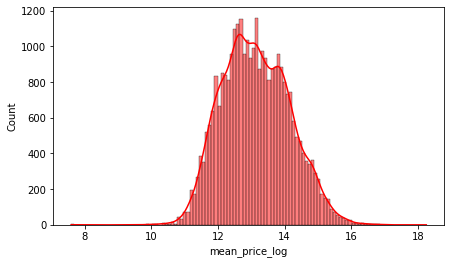

In [10]:
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

df.sort_values(by='passport_id', inplace=True)
df.reset_index(drop=1, inplace=True)

df['mean_price_log'] = np.log(df['mean_price']) 

plt.figure(figsize=(7,4))
sns.histplot(df['mean_price_log'], kde=True, color='r')
plt.show()

In [11]:
print(df['days_ago'].min(), df['days_ago'].max())
print(df['mean_n_years'].min(), df['mean_n_years'].max())

0 3738
0.0 73.0


In [12]:
from sklearn.preprocessing import StandardScaler

cd1 = df['n_ads'].quantile(q=0.99)
cd2 = df['mean_n_years'].quantile(q=0.99)
cd3 = df['days_ago'].quantile(q=0.99)
df_after_conditions = df[(df['n_ads'] < cd1) & (df['mean_n_years'] < cd2) & (df['days_ago'] < cd3)]

# df_after_conditions.head(3)

new_df = df_after_conditions[['n_ads', 'n_types', 'days_ago', 'mean_price_log'
                            , 'mean_n_years', 'buyer']]

scaler = StandardScaler()
scaled_arr = scaler.fit_transform(new_df)

scaled_data = pd.DataFrame(scaled_arr,
                           columns=new_df.columns,
                           index=new_df.index)

scaled_data.shape[0]

29763

In [13]:
scaled_data.head()

,n_ads,n_types,days_ago,mean_price_log,mean_n_years,buyer
0,6.558351,2.719888,1.000688,1.962220,-1.094520,-0.581036
1,-0.204847,1.618180,2.455233,1.486273,-0.630965,-0.581036
2,-0.543007,-0.218000,-1.204340,0.594066,-0.718880,1.721064
3,-0.543007,-0.952472,-0.662754,0.938961,-1.539416,-0.581036
4,-0.373927,-0.952472,0.381733,2.109985,-1.598025,-0.581036


Подберите параметр eps для алгоритма DBSCAN по метрике silhouette_score. Для DBSCAN  зафиксируйте n_jobs=1

Перебор eps сделайте по следующей сетке: 0.1, 0.3, 0.5, 0.7, 1, 1.5, 2.

Остальные параметры оставьте дефолтными (т.е. всего 7 вариантов для перебора).

silhouette_score считайте только если получилось не менее 2 реальных кластеров (не считая "шумового" кластера с меткой -1). В противном случае можно считать, что метрика равна -100.

Также тут может возникнуть вопрос, на каких данных считать silhouette_score: на всех точках или только на "нешумовых" кластерах. С одной стороны, вроде бы надо при расчёте исключить точки с меткой -1, т.к. -1 это "ненастоящий" кластер. С другой стороны, если мы так сделаем, лучший скор может получиться у кластеризации, которая почти всем точкам назначила -1 (проверьте это).

В рамках этого задания пойдём самым простым путём: считаем silhouette_score на всех точках. Но в реальной жизни стоило бы рассмотреть более сложные подходы (например, считать только на "нешумовых" кластерах, но потом умножать на некий штраф за долю точек с меткой -1, т.е. что-то вроде score = silhouette * coverage).

Определите, при каком eps получилось лучшее значение метрики.

Обучите DBSCAN с таким значением eps. Получите метки кластеров.

Проверьте, сколько кластеров получилось.

В поле ниже через запятую и пробел введите три значения, полученные на этом шаге:

Чему равно лучшее значение метрики. Округлите до 2 знаков после точки.
При каком eps получилось лучшее значение метрики.
Сколько кластеров получилось при использовании такого eps.

In [15]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [49]:
import itertools 

dbscan_grid = {
    'eps': [0.1, 0.3, 0.5, 0.7, 1, 1.5, 2],
}

dbscan = DBSCAN()

dbscan_keys, dbscan_values = zip(*dbscan_grid.items())
# dbscan_keys, dbscan_values
dbscan_permutation = [dict(zip(dbscan_keys,v)) for v in itertools.product(*dbscan_values)]

silhouttes = []
set_clusters = []

for param in dbscan_permutation:
    dbscan.set_params(**param)
    dbscan.fit(scaled_data)
    result = dbscan.labels_
    
    n_clusters = len(set(result)) - (1 if -1 in result else 0)
    if n_clusters >= 2:
        score = silhouette_score(scaled_data, result)
    else:
        score.append(-100)
        
    silhouttes.append(score)
    set_clusters.append(n_clusters)
        
print(f"Лучшее значение выбранной метрики равно {round(max(silhouttes),2)}")
print(f"Достигается при параметрах {dbscan_permutation[silhouttes.index(max(silhouttes))]}")
print(f"Кластеров при таком значении метрики: {set_clusters[silhouttes.index(max(silhouttes))]}")
    

Лучшее значение выбранной метрики равно 0.24
Достигается при параметрах {'eps': 1.5}
Кластеров при таком значении метрики: 2


Проверьте количество пользователей, которое попало в каждый из кластеров.

Как вы считаете, насколько удачным получилось разбиение на кластеры?

Через запятую и пробел напишите, сколько наблюдений не попало ни в один кластер и сколько содержит каждый кластер, в порядке возрастания лейблов кластеров.

Например, если у вас получилось 42 значения с меткой -1 и три кластера 0, 1, 2 с количеством точек 456, 789, 1024, то введите 42, 456, 789, 1024.


In [54]:
dbscan.set_params(**dbscan_permutation[silhouttes.index(max(silhouttes))])
dbscan.fit(scaled_data)
result = dbscan.labels_
result

array([0, 0, 1, ..., 0, 0, 0])

In [65]:
uniq, cnts = np.unique(result, return_counts=True)
res = np.asarray((uniq, cnts)).T
print(res)
print(f"Ответ: {list(map(lambda x: x[1], res))}")

[[   -1    31]
 [    0 22230]
 [    1  7502]]
Ответ: [31, 22230, 7502]


### Давайте проверим, что предложит KMeans.

In [67]:
from sklearn.cluster import KMeans
from tqdm import tqdm

С помощью все того же silhouette_score найдите оптимальное количество кластеров для алгоритма Kmeans в диапазоне от 3 до 10. Для воспроизводимости в Kmeans используйте гиперпараметры random_state=42 и n_init=1.

Через запятую и пробел введите лучшее значение метрики (округлите до 2 знаков) и найденное оптимальное количество кластеров для Kmeans. Например, 0.42, 8.

In [71]:
scores = {}
for i in range(3,11):
    km = KMeans(n_clusters=i, random_state=42, n_init=1)
    labels = km.fit_predict(scaled_data)
    scores[i] = silhouette_score(scaled_data, labels)
    
    
scores

{3: 0.2078370891959297,
 4: 0.25820646534206115,
 5: 0.24758902167248617,
 6: 0.25357512575681407,
 7: 0.2194918439316475,
 8: 0.20554205991860822,
 9: 0.20657240877578392,
 10: 0.2016509872357886}

In [84]:
res = max(scores.items(), key=lambda x: x[1])
print(f"{res[0]}, {round(res[1],2)}""")

4, 0.26


#### Задача 4. Обучение K-MEANS


Обучите KMeans с оптимальным количеством кластеров и получите результат с номерами кластеров. При обучении не забудьте установить random_state=42, n_init=1.

Вернёмся к датасету, который у нас был после фильтрации по 99-квантилям, ещё до выделения нужных столбцов и до масштабирования.

Создайте копию этого датафрейма. И добавьте туда столбец cluster с номерами кластеров от KMeans. Теперь у нас в каждой строке есть данные пользователей и назначенный номер кластера. Эти данные будем использовать для интерпретации результатов.

Для начала посмотрите количество пользователей в каждом кластере.

Постройте bar chart для визуализации результатов. Получилось ли распределение по кластерам более удачным, чем для DBSCAN?

Сколько пользователей в самом маленьком кластере?

In [89]:
km.set_params(n_clusters=res[0]
              , random_state=42, n_init=1
             )
km.fit(scaled_data, silhouette_score)
res_km = km.labels_


unique, counts = np.unique(res_km, return_counts=True)
res = np.asarray((unique, counts)).T

In [90]:
res

array([[    0, 11927],
       [    1,  7252],
       [    2,  2015],
       [    3,  8569]])

In [95]:
kmeans_data = df_after_conditions.copy()
# kmeans_data.head()
kmeans_data['cluster'] = res_km
kmeans_data.head()

,passport_id,execution_date,global_id,created_at,user_type_id,user_type_name,user_type_changed_at,user_type_cars_id,user_type_cars_name,user_type_cars_changed_at,...,mean_price,mean_year,n_types,top_type,mean_transaction,days_ago,mean_n_years,buyer,mean_price_log,cluster
0,123463130,2023-01-31,123456861,2009-04-03 19:46:43,777,profi,2023-01-31 12:44:40,0,cars_simple,2106-02-07 06:28:16,...,3.626054e+06,2015.204593,11,252,119.732143,386,7.795407,0,15.103656,2
1,123463864,2023-01-31,123457429,2009-04-05 17:11:29,0,simple_user,2106-02-07 06:28:16,0,cars_simple,2106-02-07 06:28:16,...,2.250214e+06,2011.250000,8,2,349.833333,574,11.750000,0,14.626536,3
2,123464158,2023-01-31,123457652,2009-04-06 12:29:57,0,simple_user,2106-02-07 06:28:16,0,cars_simple,2106-02-07 06:28:16,...,9.200000e+05,2012.000000,3,-4,158.333333,101,11.000000,1,13.732129,1
3,123464314,2023-01-31,123457752,2009-04-06 18:20:36,0,simple_user,2106-02-07 06:28:16,0,cars_simple,2106-02-07 06:28:16,...,1.300000e+06,2019.000000,1,1,0.000000,171,4.000000,0,14.077875,3
4,123465872,2023-01-31,123458930,2009-04-11 19:54:29,0,simple_user,2106-02-07 06:28:16,0,cars_simple,2106-02-07 06:28:16,...,4.205000e+06,2019.500000,1,3,0.000000,306,3.500000,0,15.251785,3


In [97]:
kmeans_data['cluster'].value_counts()

0    11927
3     8569
1     7252
2     2015
Name: cluster, dtype: int64

<BarContainer object of 4 artists>

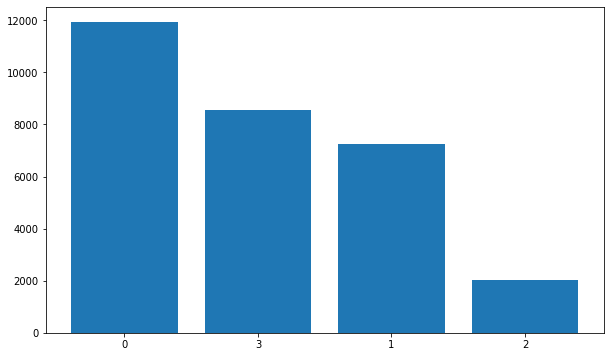

In [101]:
cnt = kmeans_data['cluster'].value_counts()
plt.figure(figsize=(10,6))
plt.bar(cnt.index.astype(str), cnt.values)

In [108]:
print(f'''Ответ: {cnt.iloc[-1]}''')

Ответ: 2015


In [112]:
kmeans_data[['cluster','n_ads', 'n_types', 'days_ago', 'mean_price', 'mean_n_years', 'buyer']].groupby('cluster').mean()

,n_ads,n_types,days_ago,mean_price,mean_n_years,buyer
cluster,,,,,,
0,3.058355,2.282217,228.992370,3.034001e+05,22.576476,0.003521
1,2.538058,4.271925,287.532819,9.578379e+05,16.361027,1.000000
2,22.249628,4.583623,345.472953,7.480136e+05,17.406206,0.098759
3,2.991248,4.612090,248.161279,1.571562e+06,10.144616,0.002217


#### Задача 5. Понижение размерности


Понизим размерность пространства признаков до 3 с помощью PCA.

Здесь мы снова работаем с данными, которые использовали для кластеризации (вместо цены её логарифм, сделано масштабирование).

Если сейчас у вас эти данные в виде numpy-массива, сделайте из них pandas-датафрейм, т.к. нам пригодятся названия столбцов.

Создайте экземпляр PCA с количеством компонент, равным 3, и random_state=42. Используйте его для получения значений новых признаков. Результат преобразуйте в pandas-датафрейм (столбцам можно дать имена вроде pca_1, pca_2, pca_3). Посмотрите на полученный датафрейм. Убедитесь, что получились ожидаемые размерности: строк осталось столько же, а столбцов стало не 6, а 3.

Постройте матрицу корреляций между старыми признаками и новыми. Это можно сделать отдельно для каждого PCA-столбца, а потом соединить вместе и превратить в датафрейм.

Визуализируйте матрицу корреляций с помощью sns.heatmap.

 какого из признаков самая сильная корреляция с какой-либо из компонент PCA (не важно, положительная или отрицательная)?

Через запятую и пробел введите:

Название признака (без кавычек, одно из этих значений: n_ads, n_types, days_ago, mean_price_log, mean_n_years).
Значение корреляции, округлённое до 3 знаков, без знака минус.
Например, n_ads, 0.876.

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
pca_data = 

In [139]:
pca = PCA(n_components=3, random_state=42)
pca.fit(scaled_data)

data_pca = pd.DataFrame(pca.transform(scaled_data), columns=[f"pca_{i+1}" for i in range(3)]
                       , index = scaled_data.index)
data_pca.head()

,pca_1,pca_2,pca_3
0,3.700069,4.181833,3.966882
1,2.391656,1.259064,0.255868
2,0.752460,-1.387330,-1.209656
3,0.655049,-1.818352,0.898968
4,1.661555,-1.373332,1.080243


In [140]:
corr = []

for i in data_pca.columns:
    c = scaled_data.corrwith(data_pca[i])
    
    corr.append(c)
    
corr_old_new = pd.concat(corr, axis=1)
corr_old_new.columns = data_pca.columns

features = [
    'n_ads',
    'n_types',
    'days_ago',
    'mean_price_log',
    'mean_n_years'
]

corr_old_new.loc[features].abs().stack().sort_values(ascending=False)

# corr_old_new

mean_price_log  pca_1    0.816673
mean_n_years    pca_1    0.741361
days_ago        pca_2    0.736353
n_ads           pca_2    0.650797
n_types         pca_1    0.596675
n_ads           pca_3    0.544355
mean_n_years    pca_2    0.395543
n_types         pca_2    0.320282
days_ago        pca_1    0.313171
mean_price_log  pca_2    0.294085
mean_n_years    pca_3    0.257719
mean_price_log  pca_3    0.159742
n_types         pca_3    0.151723
n_ads           pca_1    0.120841
days_ago        pca_3    0.101282
dtype: float64

<Axes: >

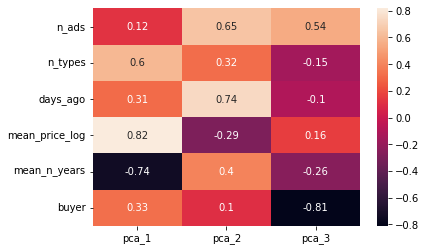

In [141]:
sns.heatmap(corr_old_new, annot=True)

In [148]:
print([round(i*100,2) for i in pca.explained_variance_ratio_])
print(f"Суммарно: {pca.explained_variance_ratio_.sum() * 100:.2f}")

print(f"""Ответ

[29.87, 22.03, 18.01]
Суммарно: 69.90


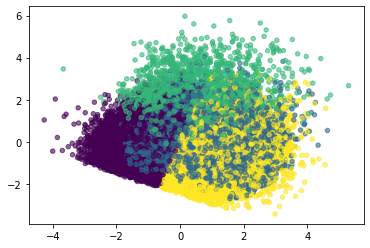

In [152]:
plt.scatter(
    data_pca['pca_1'],
    data_pca['pca_2'], 
    c = kmeans_data['cluster'], 
    cmap='viridis',
    alpha=0.6,
    s=20
)
